# 03 — Área queimada: limiar, polígonos e validação com o MapBiomas Fogo

**Projeto:** Área queimada no Parque Nacional da Chapada das Mesas (MA), estação seca de 2024
**Bootcamp:** Space Tech Bootcamp 2026 — Future Tech Leaders Brasil

Este notebook segue a orientação do Emanuel (05/11/2026):
1. **dNBR acumulado entre maio e outubro**, que capta onde houve mudança brusca do NBR na estação seca.
2. **Limiar a partir do histograma**, por exemplo 0,20, aplicado sobre o dNBR.
3. **Conectividade dos pixels** (remove ruído) e **vetorização**, que gera **polígonos de área queimada** de 2024.
4. **Validação com o MapBiomas Fogo**, a "chave de ouro".

**Dois métodos são comparados**, ambos com o mesmo limiar (0,20):
- **dNBR acumulado** (maio − outubro), sugerido pelo Emanuel;
- **dNBR mensal máximo**: a maior queda de NBR entre dois meses seguidos (jun a out), da proposta original. Ele detecta a queimada **antes da rebrota** e acumula **menos efeito da seca**.

No primeiro teste (05/11), o **dNBR mensal máximo concordou mais com o MapBiomas em todos os limiares**: Dice de 0,48 contra 0,38 no limiar 0,20. Por isso ele é o **método principal** (`METODO = 'mensal'`), e o acumulado fica como comparação. Para refazer tudo com o acumulado, basta trocar para `METODO = 'acumulado'` na Etapa 1.

O notebook mantém a parte de **série temporal** do projeto: cada pixel queimado recebe o **mês da queima** (o mês com a maior queda de NBR), e comparamos mês a mês com o MapBiomas.

**Não é preciso desenhar nada.** As amostras do notebook 02, se estiverem no Drive, aparecem no histograma como apoio.

> Execute **célula por célula** (Shift + Enter). Tempo estimado: 20 a 30 minutos, a maior parte esperando o Earth Engine.

## Etapa 0 — Conexão e Google Drive

In [1]:
!pip install -q geemap

In [2]:
import ee

PROJETO = 'lirun-94f92'
ee.Authenticate()
ee.Initialize(project=PROJETO)
print('Earth Engine conectado ao projeto:', PROJETO)

Earth Engine conectado ao projeto: lirun-94f92


In [3]:
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os, json, shutil, urllib.request
from IPython.display import Image, display
from google.colab import drive

drive.mount('/content/drive')
PASTA = '/content/drive/MyDrive/area-queimada-chapada-mesas'
os.makedirs(PASTA, exist_ok=True)
os.makedirs('resultados/figuras', exist_ok=True)
os.makedirs('resultados/tabelas', exist_ok=True)
print('Pasta no Drive:', PASTA)

Mounted at /content/drive
Pasta no Drive: /content/drive/MyDrive/area-queimada-chapada-mesas


## Etapa 1 — Parâmetros

- **LIMIAR = 0,20:** valor sugerido pelo Emanuel. Ele fica entre os dois limiares que testamos no notebook 02 (0,09 superestimou e 0,27 subestimou). O histograma da Etapa 3 serve para conferir se ele faz sentido.
- **LIMIARES_TESTE:** para mostrar **o quanto o resultado depende do limiar** (análise de sensibilidade). É um ótimo slide para a apresentação.
- **MESES_MAPBIOMAS:** comparamos com as queimadas que o MapBiomas registrou **de junho a outubro**, o mesmo período coberto pelo nosso dNBR (maio = antes).

In [4]:
ANO = 2024
METODO = 'mensal'                   # 'mensal' (principal) ou 'acumulado'
MES_ANTES = 5                       # maio
MES_DEPOIS = 10                     # outubro
MESES = [6, 7, 8, 9, 10]
LIMIAR = 0.20                       # limiar principal
LIMIARES_TESTE = [0.10, 0.15, 0.20, 0.25, 0.30]
MIN_PIXELS = 3                      # manchas menores que isso são descartadas
LIMIAR_NUVEM = 0.60
ESCALA = 20

MB_ANUAL = 'projects/mapbiomas-public/assets/brazil/fire/collection5/mapbiomas_fire_collection5_annual_burned_v1'
MB_MENSAL = 'projects/mapbiomas-public/assets/brazil/fire/collection5/mapbiomas_fire_collection5_monthly_burned_v1'
MESES_MAPBIOMAS = MESES
NOMES_MES = {5: 'mai', 6: 'jun', 7: 'jul', 8: 'ago', 9: 'set', 10: 'out'}

## Etapa 2 — Parque, composições mensais, dNBR acumulado e dNBR mensal

In [5]:
wdpa = ee.FeatureCollection('WCMC/WDPA/current/polygons')
parque = (wdpa.filter(ee.Filter.eq('ISO3', 'BRA'))
              .filter(ee.Filter.stringContains('NAME', 'Chapada Das Mesas')))
area = parque.geometry()
AREA_PARQUE = area.area(maxError=10).divide(1e4).getInfo()
print(f'Área do parque: {AREA_PARQUE:,.0f} ha')

s2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
csplus = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')

def mascarar(img):
    return img.updateMask(img.select('cs_cdf').gte(LIMIAR_NUVEM)).select(['B4', 'B8A', 'B12'])

colecao = (s2.filterBounds(area)
             .filterDate(ee.Date.fromYMD(ANO, MES_ANTES, 1), ee.Date.fromYMD(ANO, MES_DEPOIS, 1).advance(1, 'month'))
             .linkCollection(csplus, ['cs_cdf'])
             .map(mascarar))

def composicao_mensal(mes):
    ini = ee.Date.fromYMD(ANO, mes, 1)
    comp = colecao.filterDate(ini, ini.advance(1, 'month')).median()
    nbr = comp.normalizedDifference(['B8A', 'B12']).rename('NBR')
    return comp.addBands(nbr).clip(area)

comps = {m: composicao_mensal(m) for m in [MES_ANTES] + MESES}

# dNBR acumulado: maio - outubro
dnbr_acum = comps[MES_ANTES].select('NBR').subtract(comps[MES_DEPOIS].select('NBR')).rename('dNBR')

# dNBR de cada mês (mês anterior - mês): usado só para descobrir QUANDO queimou
dnbr_mes = {m: comps[m - 1].select('NBR').subtract(comps[m].select('NBR')).rename('dNBR') for m in MESES}

# dNBR mensal máximo: a maior queda de NBR entre dois meses seguidos
dnbr_max = ee.ImageCollection([dnbr_mes[m] for m in MESES]).max().rename('dNBR')

INDICES = {'acumulado': dnbr_acum, 'mensal': dnbr_max}
NOMES_METODO = {'acumulado': 'dNBR acumulado mai→out', 'mensal': 'dNBR mensal máximo'}
indice = INDICES[METODO]
print('Pronto. Método principal:', NOMES_METODO[METODO])

Área do parque: 160,638 ha
Pronto. Método principal: dNBR mensal máximo


## Etapa 3 — Histograma do índice principal

Sorteamos 5.000 pixels do parque. As **linhas tracejadas** são os limiares de teste; a **linha preta** é o limiar principal.

Se as suas amostras do notebook 02 estiverem no Drive, aparecem também os valores de dNBR acumulado **dentro dos polígonos** que você desenhou: em **vermelho** os queimados e em **verde** os não queimados.

**O que observar:** o pico principal (áreas que só secaram) e a **cauda à direita** (queimadas). Um bom limiar fica **depois do pico**, no começo da cauda.

dNBR mensal máximo no parque (5.000 pixels):
count    5000.000
mean        0.079
std         0.075
min        -0.018
25%         0.029
50%         0.056
75%         0.098
max         0.654
Amostras queimado: n=175, mediana=0.769, mín=0.440, máx=0.952
Amostras não queimado: n=300, mediana=0.021, mín=-0.009, máx=0.074


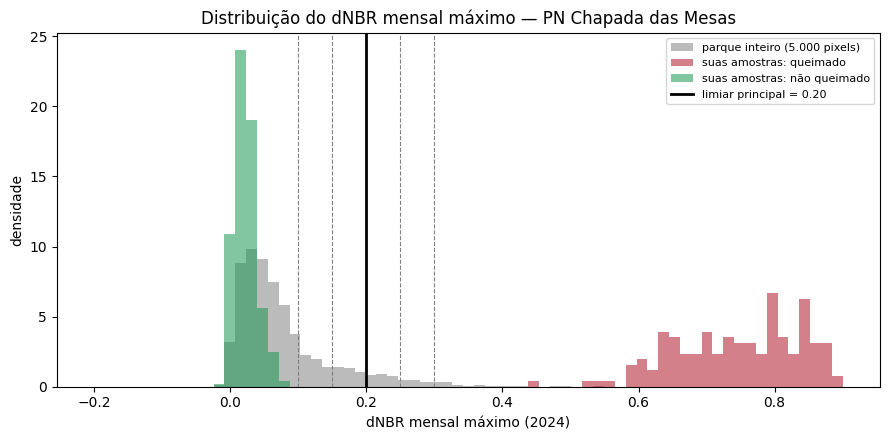

In [6]:
amostra = indice.sample(region=area, scale=ESCALA, numPixels=5000, seed=42, geometries=False)
valores = pd.Series(amostra.aggregate_array('dNBR').getInfo())
print(f'{NOMES_METODO[METODO]} no parque (5.000 pixels):')
print(valores.describe().round(3).to_string())

def carregar(caminho):
    with open(caminho) as f:
        dados = json.load(f)
    return ee.FeatureCollection([ee.Feature(f) for f in dados['features']]) if dados.get('features') else None

amostras = {}
for nome, arq, classe in [('queimado', f'{PASTA}/amostras_queimado.geojson', 1),
                          ('não queimado', f'{PASTA}/amostras_nao_queimado.geojson', 0)]:
    if os.path.exists(arq):
        fc = carregar(arq)
        if fc is not None:
            pts = indice.sample(region=fc.geometry(), scale=ESCALA, numPixels=300, seed=1, geometries=False)
            amostras[nome] = pd.Series(pts.aggregate_array('dNBR').getInfo())
for nome, s in amostras.items():
    print(f'Amostras {nome}: n={len(s)}, mediana={s.median():.3f}, mín={s.min():.3f}, máx={s.max():.3f}')

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.linspace(-0.2, 0.9, 70)
ax.hist(valores, bins=bins, color='#bbbbbb', label='parque inteiro (5.000 pixels)', density=True)
cores = {'queimado': '#b2182b', 'não queimado': '#1a9850'}
for nome, s in amostras.items():
    ax.hist(s, bins=bins, color=cores[nome], alpha=0.55, label=f'suas amostras: {nome}', density=True)
for t in LIMIARES_TESTE:
    ax.axvline(t, color='gray', linestyle='--', linewidth=0.8)
ax.axvline(LIMIAR, color='black', linewidth=2, label=f'limiar principal = {LIMIAR:.2f}')
ax.set_xlabel(f'{NOMES_METODO[METODO]} (2024)')
ax.set_ylabel('densidade')
ax.set_title(f'Distribuição do {NOMES_METODO[METODO]} — PN Chapada das Mesas')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'resultados/figuras/histograma_{METODO}.png', dpi=150)
plt.show()

## Etapa 4 — Classificação: limiar + conectividade

1. Pixel com **índice > limiar** é marcado como queimado (o índice é o do método principal).
2. **Conectividade:** contamos quantos pixels queimados estão ligados entre si (vizinhança de 8). Manchas com menos de `MIN_PIXELS` pixels são descartadas como ruído.
3. Calculamos a área em hectares.

In [7]:
def classificar(limiar, metodo=METODO):
    q = INDICES[metodo].gt(limiar).selfMask()
    tamanho = q.connectedPixelCount(maxSize=50, eightConnected=True)
    return q.updateMask(tamanho.gte(MIN_PIXELS)).rename('queimado')

def area_ha(mascara, escala=ESCALA):
    return ee.Image.pixelArea().divide(1e4).updateMask(mascara).reduceRegion(
        ee.Reducer.sum(), area, scale=escala, maxPixels=1e13, tileScale=4).get('area').getInfo() or 0.0

queimado = classificar(LIMIAR)
AREA_NOSSA = area_ha(queimado)
print(f'{NOMES_METODO[METODO]}, limiar {LIMIAR:.2f}: {AREA_NOSSA:,.0f} ha queimados = {AREA_NOSSA / AREA_PARQUE * 100:.1f}% do parque')

dNBR mensal máximo, limiar 0.20: 12,202 ha queimados = 7.6% do parque


## Etapa 5 — MapBiomas Fogo (referência)

Carregamos o **MapBiomas Fogo, Coleção 5** (Landsat, 30 m):
- **mensal:** cada pixel traz o mês em que queimou (1 a 12). Usamos **junho a outubro**, o mesmo período do nosso dNBR;
- **anual:** tudo o que queimou em 2024, para contexto.

Se aparecer erro aqui, provavelmente o nome do asset mudou. Copie a mensagem e me mande.

In [8]:
mb_mensal_img = ee.Image(MB_MENSAL)
bandas = mb_mensal_img.bandNames().getInfo()
print('Últimas bandas do MapBiomas mensal:', bandas[-3:])

mb_mes = mb_mensal_img.select(f'burned_monthly_{ANO}').clip(area)
mb_periodo = mb_mes.gte(min(MESES_MAPBIOMAS)).And(mb_mes.lte(max(MESES_MAPBIOMAS))).selfMask()
mb_anual = ee.Image(MB_ANUAL).select(f'burned_area_{ANO}').clip(area).gt(0).selfMask()

AREA_MB_PERIODO = area_ha(mb_periodo, 30)
AREA_MB_ANUAL = area_ha(mb_anual, 30)
print(f'MapBiomas {ANO}, jun–out: {AREA_MB_PERIODO:,.0f} ha ({AREA_MB_PERIODO / AREA_PARQUE * 100:.1f}% do parque)')
print(f'MapBiomas {ANO}, ano todo: {AREA_MB_ANUAL:,.0f} ha ({AREA_MB_ANUAL / AREA_PARQUE * 100:.1f}% do parque)')

Últimas bandas do MapBiomas mensal: ['burned_monthly_2023', 'burned_monthly_2024', 'burned_monthly_2025']
MapBiomas 2024, jun–out: 10,986 ha (6.8% do parque)
MapBiomas 2024, ano todo: 16,136 ha (10.0% do parque)


## Etapa 6 — Validação: concordância com o MapBiomas e sensibilidade ao limiar

Comparamos pixel a pixel, numa grade de 30 m (a do MapBiomas):

| | MapBiomas: queimado | MapBiomas: não queimado |
|---|---|---|
| **Nosso: queimado** | acerto (VP) | **comissão** (FP) |
| **Nosso: não queimado** | **omissão** (FN) | acerto (VN) |

- **Erro de omissão** = FN / (VP + FN): parte do que o MapBiomas viu queimar e nós perdemos.
- **Erro de comissão** = FP / (VP + FP): parte do que chamamos de queimado e o MapBiomas não.
- **Coeficiente de Dice** = 2·VP / (2·VP + FP + FN): concordância geral da área queimada, de 0 a 1 (1 = idêntico).

> O MapBiomas também é um mapa produzido por modelo (Landsat, 30 m), não "verdade de campo". Por isso falamos em **concordância com um produto de referência independente**, e não em acurácia absoluta.

O limiar principal (0,20) foi definido **antes** de olhar o MapBiomas. A tabela com os outros limiares serve para **transparência**: mostra o quanto o resultado depende dessa escolha.

In [9]:
ref = mb_periodo.unmask(0).gt(0)

def validar(mascara):
    nosso = mascara.unmask(0).gt(0)
    codigo = nosso.multiply(2).add(ref).rename('codigo')   # 0 nenhum | 1 só MapBiomas | 2 só nosso | 3 ambos
    soma = ee.Image.pixelArea().divide(1e4).addBands(codigo).reduceRegion(
        ee.Reducer.sum().group(groupField=1, groupName='codigo'),
        area, scale=30, maxPixels=1e13, tileScale=4)
    g = {int(x['codigo']): x['sum'] for x in soma.get('groups').getInfo()}
    vp, fn, fp, vn = g.get(3, 0.0), g.get(1, 0.0), g.get(2, 0.0), g.get(0, 0.0)
    return {
        'área nossa (ha)': vp + fp,
        'área MapBiomas (ha)': vp + fn,
        'acerto VP (ha)': vp,
        'omissão (%)': fn / (vp + fn) * 100 if vp + fn else np.nan,
        'comissão (%)': fp / (vp + fp) * 100 if vp + fp else np.nan,
        'Dice': 2 * vp / (2 * vp + fp + fn) if (2 * vp + fp + fn) else np.nan,
        'concordância global (%)': (vp + vn) / (vp + vn + fp + fn) * 100,
    }

linhas = []
for metodo in ['acumulado', 'mensal']:
    print(NOMES_METODO[metodo])
    for t in LIMIARES_TESTE:
        r = {'método': NOMES_METODO[metodo], 'limiar': t, **validar(classificar(t, metodo))}
        linhas.append(r)
        print(f"  limiar {t:.2f}: {r['área nossa (ha)']:>9,.0f} ha | omissão {r['omissão (%)']:5.1f}% | "
              f"comissão {r['comissão (%)']:5.1f}% | Dice {r['Dice']:.2f}")

sens = pd.DataFrame(linhas).round(2)
sens.to_csv('resultados/tabelas/sensibilidade_e_comparacao_metodos.csv', index=False)
sens[['método', 'limiar', 'área nossa (ha)', 'omissão (%)', 'comissão (%)', 'Dice']]

dNBR acumulado mai→out
  limiar 0.10:    65,754 ha | omissão  13.6% | comissão  85.6% | Dice 0.25
  limiar 0.15:    40,863 ha | omissão  25.9% | comissão  80.1% | Dice 0.31
  limiar 0.20:    24,444 ha | omissão  38.2% | comissão  72.2% | Dice 0.38
  limiar 0.25:    14,625 ha | omissão  51.0% | comissão  63.2% | Dice 0.42
  limiar 0.30:     9,006 ha | omissão  64.0% | comissão  56.1% | Dice 0.40
dNBR mensal máximo
  limiar 0.10:    37,604 ha | omissão  14.3% | comissão  75.0% | Dice 0.39
  limiar 0.15:    21,764 ha | omissão  30.0% | comissão  64.7% | Dice 0.47
  limiar 0.20:    12,065 ha | omissão  49.3% | comissão  53.8% | Dice 0.48
  limiar 0.25:     6,015 ha | omissão  69.4% | comissão  44.2% | Dice 0.39
  limiar 0.30:     2,668 ha | omissão  84.5% | comissão  36.3% | Dice 0.25


,método,limiar,área nossa (ha),omissão (%),comissão (%),Dice
0,dNBR acumulado mai→out,0.10,65754.41,13.64,85.57,0.25
1,dNBR acumulado mai→out,0.15,40862.69,25.92,80.08,0.31
2,dNBR acumulado mai→out,0.20,24444.22,38.22,72.23,0.38
3,dNBR acumulado mai→out,0.25,14625.47,51.00,63.19,0.42
4,dNBR acumulado mai→out,0.30,9006.06,63.97,56.05,0.40
5,dNBR mensal máximo,0.10,37604.01,14.28,74.96,0.39
6,dNBR mensal máximo,0.15,21764.16,29.99,64.66,0.47
7,dNBR mensal máximo,0.20,12065.06,49.28,53.82,0.48
8,dNBR mensal máximo,0.25,6015.28,69.44,44.19,0.39
9,dNBR mensal máximo,0.30,2667.82,84.53,36.31,0.25


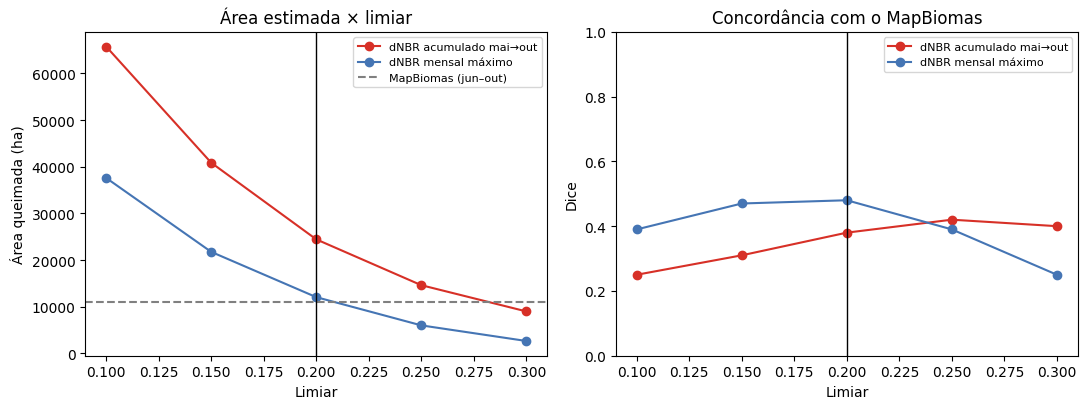

In [10]:
cores = {'dNBR acumulado mai→out': '#d73027', 'dNBR mensal máximo': '#4575b4'}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for metodo, d in sens.groupby('método'):
    ax1.plot(d['limiar'], d['área nossa (ha)'], marker='o', color=cores[metodo], label=metodo)
    ax2.plot(d['limiar'], d['Dice'], marker='o', color=cores[metodo], label=metodo)
ax1.axhline(AREA_MB_PERIODO, color='gray', linestyle='--', label='MapBiomas (jun–out)')
for ax in (ax1, ax2):
    ax.axvline(LIMIAR, color='black', linewidth=1)
    ax.set_xlabel('Limiar')
ax1.set_ylabel('Área queimada (ha)'); ax1.set_title('Área estimada × limiar'); ax1.legend(fontsize=8)
ax2.set_ylabel('Dice'); ax2.set_ylim(0, 1); ax2.set_title('Concordância com o MapBiomas'); ax2.legend(fontsize=8)
plt.tight_layout()
plt.savefig('resultados/figuras/sensibilidade_e_comparacao_metodos.png', dpi=150)
plt.show()

## Etapa 7 — Série temporal: em que mês cada área queimou?

Para cada pixel classificado como queimado, olhamos o **dNBR de cada mês** e atribuímos o pixel ao **mês da maior queda de NBR**. Assim, a soma dos meses é **igual** à área total da Etapa 4, sem dupla contagem.

Depois comparamos com o mês registrado pelo MapBiomas.

> **Atenção ao mês de junho:** o dNBR de junho (maio → junho) inclui o início da secagem da vegetação, que pode ser confundido com fogo. Se tivermos bem mais área em junho do que o MapBiomas, essa é a explicação provável. É um bom ponto para a discussão.

In [11]:
pilha = ee.ImageCollection([
    dnbr_mes[m].addBands(ee.Image.constant(m).toInt().rename('mes')) for m in MESES])
mes_queima = pilha.qualityMosaic('dNBR').select('mes').updateMask(queimado).rename('mes')

def area_por_mes(img_mes, escala):
    soma = ee.Image.pixelArea().divide(1e4).addBands(img_mes).reduceRegion(
        ee.Reducer.sum().group(groupField=1, groupName='mes'), area, scale=escala, maxPixels=1e13, tileScale=4)
    return {int(g['mes']): g['sum'] for g in soma.get('groups').getInfo()}

nosso_mes = area_por_mes(mes_queima, ESCALA)
mb_mes_area = area_por_mes(mb_mes.updateMask(mb_periodo).rename('mes'), 30)

serie = pd.DataFrame({
    'mês': [NOMES_MES[m] for m in MESES],
    'nosso (ha)': [nosso_mes.get(m, 0.0) for m in MESES],
    'MapBiomas (ha)': [mb_mes_area.get(m, 0.0) for m in MESES],
})
serie['nosso acumulado (ha)'] = serie['nosso (ha)'].cumsum()
serie['MapBiomas acumulado (ha)'] = serie['MapBiomas (ha)'].cumsum()
serie = serie.round(1)
serie.to_csv('resultados/tabelas/serie_mensal_nosso_vs_mapbiomas.csv', index=False)
serie

,mês,nosso (ha),MapBiomas (ha),nosso acumulado (ha),MapBiomas acumulado (ha)
0,jun,6612.1,2101.8,6612.1,2101.8
1,jul,1637.0,2169.8,8249.1,4271.6
2,ago,292.9,806.5,8541.9,5078.1
3,set,2152.1,5012.0,10694.0,10090.1
4,out,1507.8,895.7,12201.8,10985.8


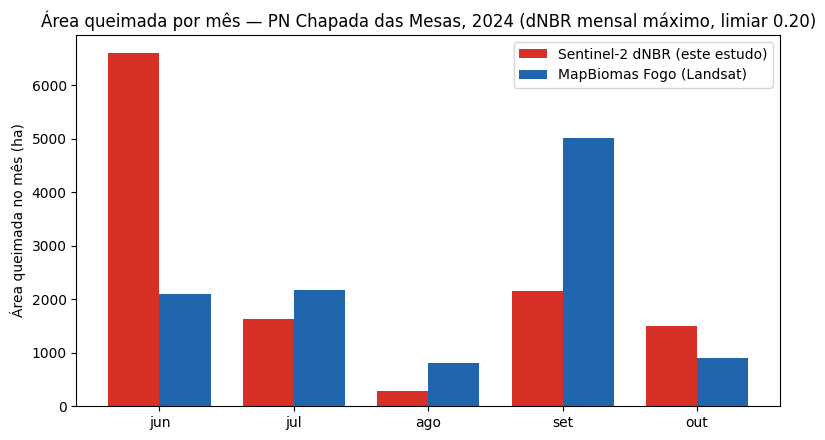

In [12]:
x = np.arange(len(MESES)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - w/2, serie['nosso (ha)'], w, color='#d73027', label='Sentinel-2 dNBR (este estudo)')
ax.bar(x + w/2, serie['MapBiomas (ha)'], w, color='#2166ac', label='MapBiomas Fogo (Landsat)')
ax.set_xticks(x); ax.set_xticklabels(serie['mês'])
ax.set_ylabel('Área queimada no mês (ha)')
ax.set_title(f'Área queimada por mês — PN Chapada das Mesas, {ANO} ({NOMES_METODO[METODO]}, limiar {LIMIAR:.2f})')
ax.legend()
plt.tight_layout()
plt.savefig('resultados/figuras/serie_mensal_nosso_vs_mapbiomas.png', dpi=150)
plt.show()

## Etapa 8 — Mapas

**Mapa interativo** (fundo de satélite). Ligue e desligue as camadas no ícone do canto superior direito:
- **Concordância:** vermelho = os dois mapas dizem queimado; laranja = só o nosso (comissão); azul = só o MapBiomas (omissão).
- **Mês da queima:** amarelo = jun, verde = jul, verde-azulado = ago, azul = set, roxo = out.

In [13]:
nosso_bin = queimado.unmask(0).gt(0)
concordancia = nosso_bin.multiply(2).add(ref).selfMask()
vis_conc = {'min': 1, 'max': 3, 'palette': ['2166ac', 'fdae61', 'b2182b']}
vis_mes = {'min': 6, 'max': 10, 'palette': ['fde725', '5ec962', '21918c', '3b528b', '440154']}
vis_falsa = {'bands': ['B12', 'B8A', 'B4'], 'min': 0, 'max': 3500}
vis_dnbr = {'min': -0.2, 'max': 0.6, 'palette': ['1a9850', 'ffffbf', 'fdae61', 'd73027', '67001f']}
contorno = ee.Image().paint(parque, 0, 2)

Map = geemap.Map(basemap='SATELLITE')
Map.centerObject(area, 10)
Map.addLayer(comps[MES_ANTES], vis_falsa, 'Falsa-cor mai', False)
Map.addLayer(comps[MES_DEPOIS], vis_falsa, 'Falsa-cor out', False)
Map.addLayer(dnbr_acum, vis_dnbr, 'dNBR acumulado', False)
Map.addLayer(dnbr_max, vis_dnbr, 'dNBR mensal máximo', False)
Map.addLayer(mes_queima, vis_mes, 'Mês da queima (nosso)', False)
Map.addLayer(concordancia, vis_conc, 'Concordância com MapBiomas')
Map.addLayer(contorno, {'palette': 'white'}, 'Limite do parque')
Map.add_legend(title='Concordância', legend_dict={
    'ambos (acerto)': 'b2182b', 'só nosso (comissão)': 'fdae61', 'só MapBiomas (omissão)': '2166ac'})
Map

Map(center=[-7.1524703258955125, -47.14468687103683], controls=(WidgetControl(options=['position', 'transparen…

Salvo: resultados/figuras/mapa_concordancia_mapbiomas_mensal.png


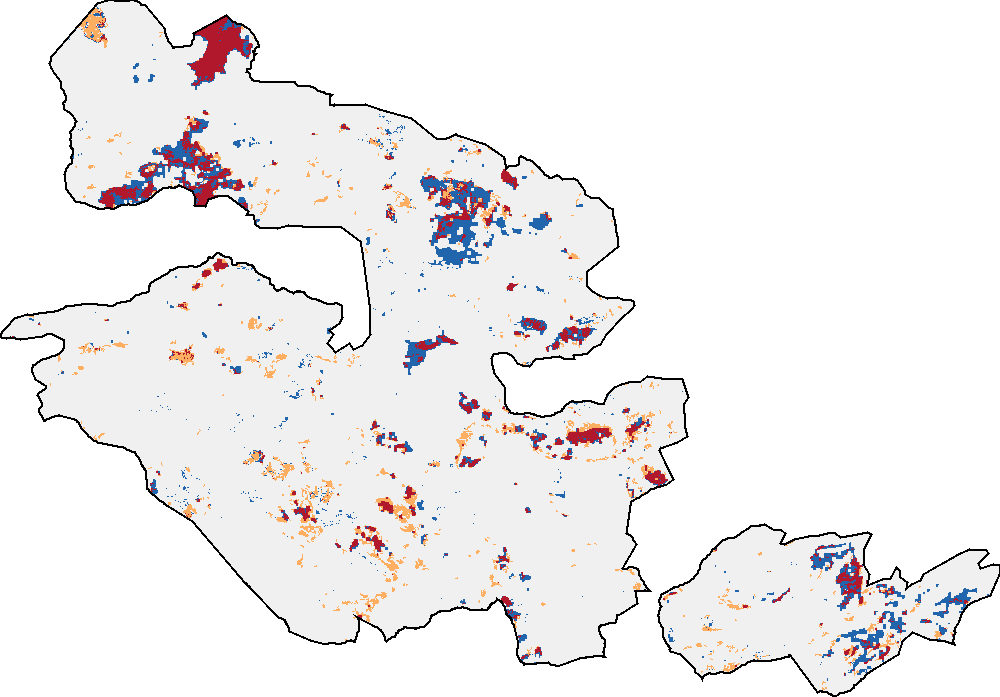

vermelho = ambos | laranja = só nosso (comissão) | azul = só MapBiomas (omissão)
Salvo: resultados/figuras/mapa_mes_queima_mensal.png


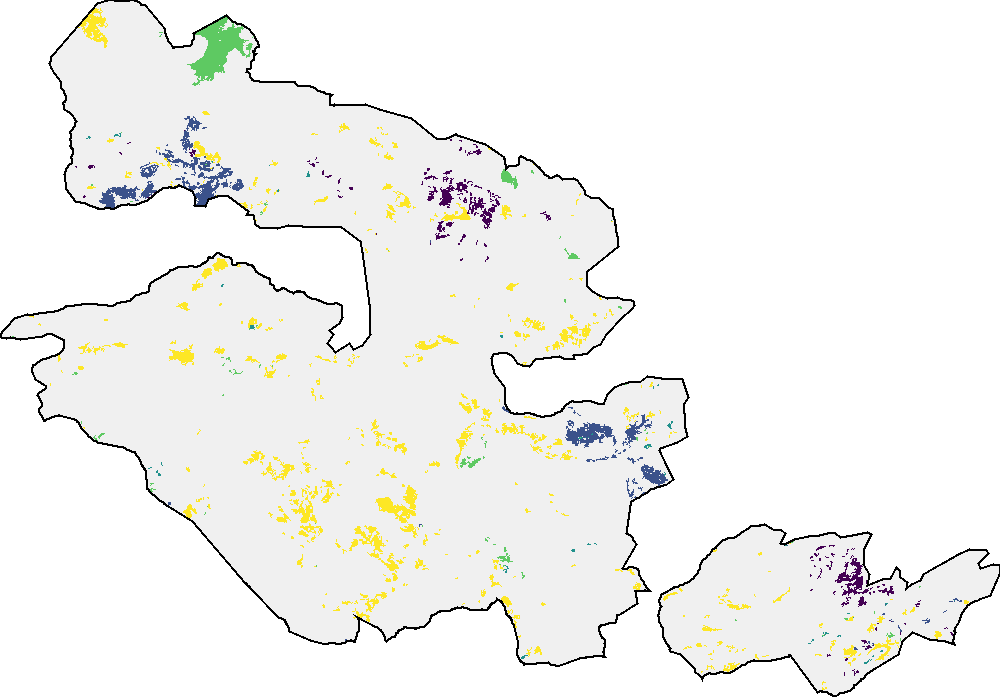

amarelo = jun | verde = jul | verde-azulado = ago | azul = set | roxo = out


In [14]:
def salvar_figura(img_vis, nome):
    fundo = ee.Image.constant(0).visualize(palette=['f0f0f0']).clip(area)
    final = fundo.blend(img_vis).blend(contorno.visualize(palette=['black']))
    url = final.getThumbURL({'region': area.bounds(), 'dimensions': 1000, 'format': 'png'})
    caminho = f'resultados/figuras/{nome}.png'
    urllib.request.urlretrieve(url, caminho)
    print('Salvo:', caminho)
    display(Image(filename=caminho, width=550))

salvar_figura(concordancia.visualize(**vis_conc), f'mapa_concordancia_mapbiomas_{METODO}')
print('vermelho = ambos | laranja = só nosso (comissão) | azul = só MapBiomas (omissão)')
salvar_figura(mes_queima.visualize(**vis_mes), f'mapa_mes_queima_{METODO}')
print('amarelo = jun | verde = jul | verde-azulado = ago | azul = set | roxo = out')

## Etapa 9 — Vetorização: polígonos de área queimada

Transformamos os pixels queimados em **polígonos** (um por mancha conectada), cada um com sua **área em hectares** e o **mês predominante** da queima. O arquivo **Shapefile** é gerado pelo Earth Engine e vai para o seu **Google Drive**, na pasta `area-queimada-chapada-mesas`. Ele pode ser aberto no QGIS e entra no GitHub.

A exportação roda **em segundo plano** e pode levar alguns minutos. A célula seguinte mostra o andamento.

In [15]:
vetores = queimado.toInt().addBands(mes_queima.toInt()).reduceToVectors(
    geometry=area, scale=ESCALA, geometryType='polygon', eightConnected=True,
    labelProperty='queimado', reducer=ee.Reducer.mode(), maxPixels=1e13, tileScale=4)
vetores = vetores.map(lambda f: f.set({
    'area_ha': f.geometry().area(maxError=1).divide(1e4),
    'mes': f.get('mode'), 'limiar': LIMIAR, 'metodo': METODO, 'ano': ANO}))

tarefa = ee.batch.Export.table.toDrive(
    collection=vetores, description=f'poligonos_area_queimada_PNCM_{ANO}_{METODO}',
    folder='area-queimada-chapada-mesas', fileFormat='SHP')
tarefa.start()
print('Exportação iniciada. Rode a próxima célula para ver o andamento.')

Exportação iniciada. Rode a próxima célula para ver o andamento.


In [22]:
st = tarefa.status()
print('Situação:', st['state'])
if st['state'] == 'COMPLETED':
    print('Pronto! O Shapefile está no seu Google Drive, pasta area-queimada-chapada-mesas.')
elif st['state'] == 'FAILED':
    print('Falhou:', st.get('error_message'))
else:
    print('Ainda processando. Espere 1 ou 2 minutos e rode esta célula de novo.')

Situação: COMPLETED
Pronto! O Shapefile está no seu Google Drive, pasta area-queimada-chapada-mesas.


In [18]:
# Resumo dos polígonos (pode levar alguns segundos)
try:
    n_pol = vetores.size().getInfo()
    maior = vetores.aggregate_max('area_ha').getInfo()
    print(f'Número de polígonos: {n_pol:,}')
    print(f'Maior polígono: {maior:,.1f} ha')
except Exception as e:
    print('Resumo indisponível agora (não impede nada):', e)

Número de polígonos: 4,290
Maior polígono: 1,043.3 ha


## Etapa 10 — Resumo e cópia para o Drive

In [19]:
v = validar(queimado)
resumo = pd.DataFrame([{
    'método': NOMES_METODO[METODO],
    'limiar': LIMIAR,
    'área queimada nossa jun–out (ha)': round(AREA_NOSSA, 1),
    '% do parque': round(AREA_NOSSA / AREA_PARQUE * 100, 1),
    'área MapBiomas jun–out (ha)': round(AREA_MB_PERIODO, 1),
    'área MapBiomas ano todo (ha)': round(AREA_MB_ANUAL, 1),
    'omissão (%)': round(v['omissão (%)'], 1),
    'comissão (%)': round(v['comissão (%)'], 1),
    'Dice': round(v['Dice'], 2),
}])
resumo.to_csv('resultados/tabelas/resumo_resultados.csv', index=False)
shutil.copytree('resultados', f'{PASTA}/resultados', dirs_exist_ok=True)
print('Resultados copiados para o Drive:', f'{PASTA}/resultados')
resumo.T

Resultados copiados para o Drive: /content/drive/MyDrive/area-queimada-chapada-mesas/resultados


,0
método,dNBR mensal máximo
limiar,0.2
área queimada nossa jun–out (ha),12201.8
% do parque,7.6
área MapBiomas jun–out (ha),10985.8
área MapBiomas ano todo (ha),16136.3
omissão (%),49.3
comissão (%),53.8
Dice,0.48


## O que me mandar

O **PDF da página** (como nos outros notebooks), ou prints de:
1. o **histograma** (Etapa 3);
2. a **tabela de sensibilidade** e o gráfico (Etapa 6);
3. a **série mensal nosso × MapBiomas** (Etapa 7);
4. o **mapa de concordância** (Etapa 8);
5. a **situação da exportação** dos polígonos (Etapa 9) e o **resumo** (Etapa 10).

Com isso fechamos os resultados e partimos para os slides.

---
*Problemas comuns*
- **Erro no MapBiomas (Etapa 5):** o nome do asset pode ter mudado. Me mande a mensagem.
- **`Computation timed out`:** troque `ESCALA = 20` por `ESCALA = 30` na Etapa 1 e rode de novo a partir dali.
- **O mapa não aparece:** rode de novo a célula do `enable_custom_widget_manager` (Etapa 0) e depois a do mapa.